<a href="https://colab.research.google.com/github/natalie400/PS-Agents/blob/main/UCS_Trailer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
"""
Uniform Cost Search (UCS) Homework Assignment
Goal: Navigate a trailer from Nairobi to Kisumu with the minimum travel distance.

Group Study Reference notes:
- State: Current town
- Step cost: Road distance in km
- Frontier: Priority Queue (heapq sorted by path cost g)
- Goal Test: Checked when expanding a node from the queue to ensure optimality!
"""

import heapq
from itertools import count  # Used as a standard tie-breaker in python heapq

# --- Configuration & Problem Setup ---
START = "Nairobi"
GOAL = "Kisumu"

# Road network data (distances in km)
ROADS = [
    ("Nairobi", "Thika", 42),
    ("Thika", "Murang'a", 40),
    ("Murang'a", "Nyeri", 65),
    ("Nyeri", "Nyahururu", 70),
    ("Nairobi", "Naivasha", 92),
    ("Naivasha", "Nakuru", 64),
    ("Naivasha", "Nyahururu", 95),
    ("Nyahururu", "Nakuru", 90),
    ("Nairobi", "Narok", 140),
    ("Narok", "Bomet", 75),
    ("Nakuru", "Mau Summit", 56),
    ("Nakuru", "Eldoret", 155),
    ("Mau Summit", "Londiani", 24),
    ("Londiani", "Muhoroni", 75),
    ("Muhoroni", "Kisumu", 45),
    ("Londiani", "Kericho", 45),
    ("Bomet", "Kericho", 55),
    ("Kericho", "Kisumu", 100),
    ("Bomet", "Kisii", 70),
    ("Kisii", "Kisumu", 115),
    ("Eldoret", "Kakamega", 90),
    ("Kakamega", "Kisumu", 55),
]


def build_graph(roads):
    """Helper to parse roads into a standard undirected adjacency list"""
    graph = {}
    for a, b, km in roads:
        graph.setdefault(a, []).append((b, km))
        graph.setdefault(b, []).append((a, km))
    return graph


def show_frontier(frontier):
    """Helper function to display current frontier states in sorted order (cheapest first)"""
    items = sorted(frontier)
    return ", ".join(f"{town} ({g})" for g, _, town, _ in items)


def uniform_cost_search(graph, start, goal):
    # Tie-breaker counter to avoid comparing lists/town strings inside heapq tuple
    tie = count()

    # Frontier tuple: (cumulative_cost_g, order_added, current_town, path_taken)
    frontier = [(0, next(tie), start, [start])]

    # Keeps track of the minimum cost we've seen to reach any town
    best_g = {start: 0}
    explored = set()
    step = 0

    print(f"UCS from {start} to {goal}\n")
    print(f"{'Step':<5}{'Expand':<12}{'g (km)':<8}Frontier after expansion")
    print("-" * 78)

    while frontier:
        # Pop node with the smallest total path cost (g)
        g, _, town, path = heapq.heappop(frontier)

        # Standard graph search check: ignore if we already found a shorter path
        if town in explored:
            continue

        step += 1
        explored.add(town)

        # Optimal Goal Test happens upon EXPANSION
        if town == goal:
            print(f"{step:<5}{town:<12}{g:<8}GOAL REACHED")
            return path, g

        notes = []
        for neighbour, km in graph[town]:
            new_g = g + km
            if neighbour in explored:
                continue

            # If we discovered a better way to get to this neighbour
            if neighbour not in best_g or new_g < best_g[neighbour]:
                best_g[neighbour] = new_g
                heapq.heappush(
                    frontier, (new_g, next(tie), neighbour, path + [neighbour])
                )
            else:
                # Record rejected paths for the step-by-step trace output
                notes.append(f"{neighbour} {new_g} rejected (have {best_g[neighbour]})")

        # Print state trace of execution
        line = show_frontier(frontier)
        print(f"{step:<5}{town:<12}{g:<8}{line}")
        for n in notes:
            print(f"{'':<25}-> {n}")

    return None, float("inf")


def main():
    graph = build_graph(ROADS)
    path, cost = uniform_cost_search(graph, START, GOAL)

    print("\n" + "=" * 78)
    if path is None:
        print("No route found.")
        return

    print("OPTIMAL PATH")
    print(" -> ".join(path))
    print("\nLeg-by-leg cost:")
    total = 0
    for a, b in zip(path, path[1:]):
        km = next(d for n, d in graph[a] if n == b)
        total += km
        print(f"  {a:<12} -> {b:<12} {km:>4} km   (cumulative {total} km)")
    print(f"\nTotal path cost: {cost} km")


if __name__ == "__main__":
    main()

UCS from Nairobi to Kisumu

Step Expand      g (km)  Frontier after expansion
------------------------------------------------------------------------------
1    Nairobi     0       Thika (42), Naivasha (92), Narok (140)
2    Thika       42      Murang'a (82), Naivasha (92), Narok (140)
3    Murang'a    82      Naivasha (92), Narok (140), Nyeri (147)
4    Naivasha    92      Narok (140), Nyeri (147), Nakuru (156), Nyahururu (187)
5    Narok       140     Nyeri (147), Nakuru (156), Nyahururu (187), Bomet (215)
6    Nyeri       147     Nakuru (156), Nyahururu (187), Bomet (215)
                         -> Nyahururu 217 rejected (have 187)
7    Nakuru      156     Nyahururu (187), Mau Summit (212), Bomet (215), Eldoret (311)
                         -> Nyahururu 246 rejected (have 187)
8    Nyahururu   187     Mau Summit (212), Bomet (215), Eldoret (311)
9    Mau Summit  212     Bomet (215), Londiani (236), Eldoret (311)
10   Bomet       215     Londiani (236), Kericho (270), Kisii (285),

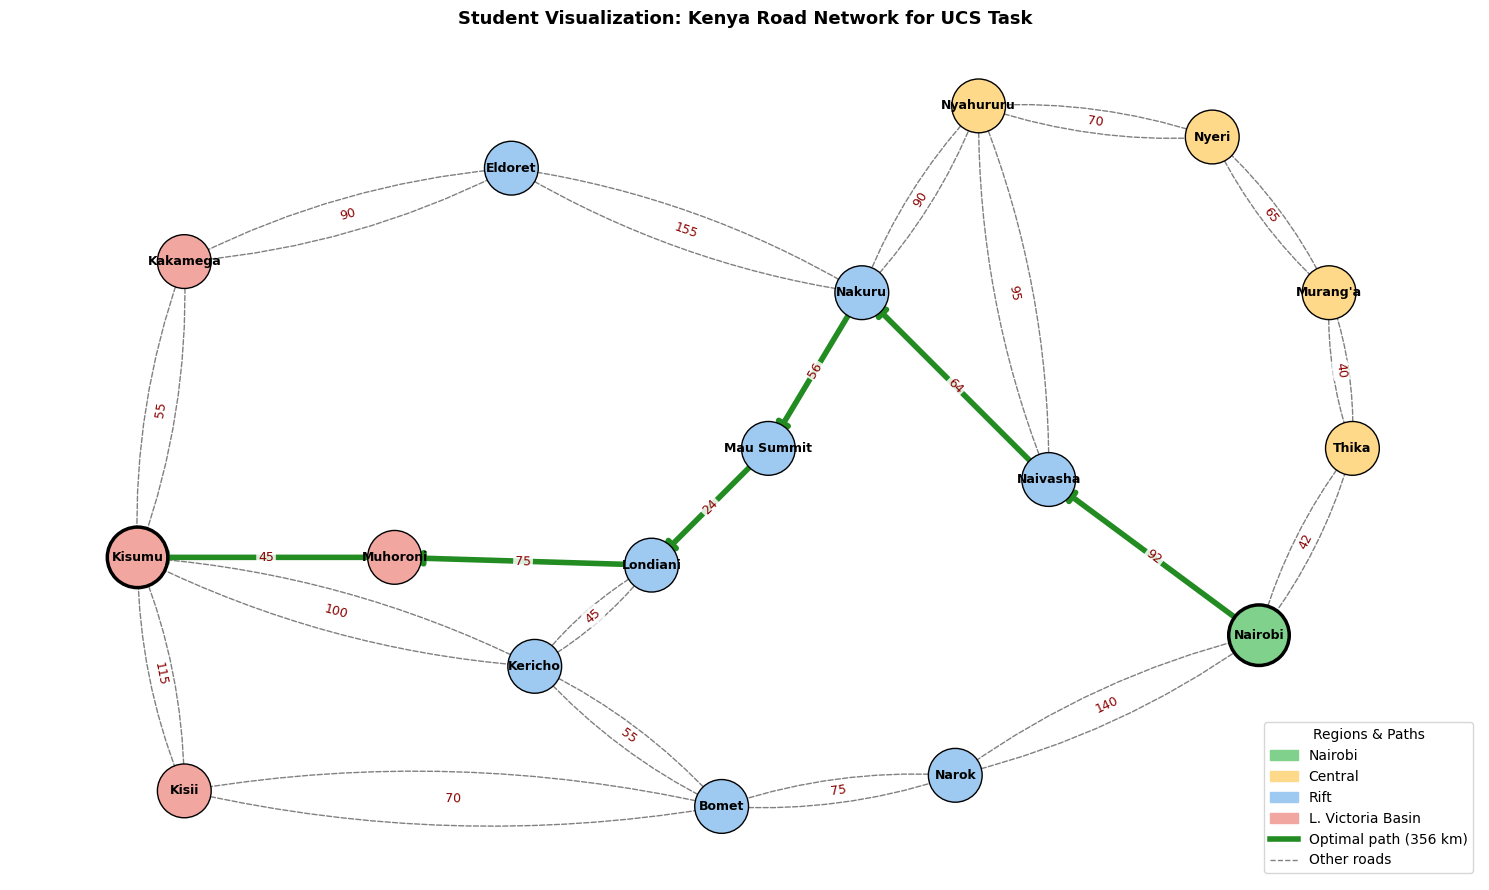

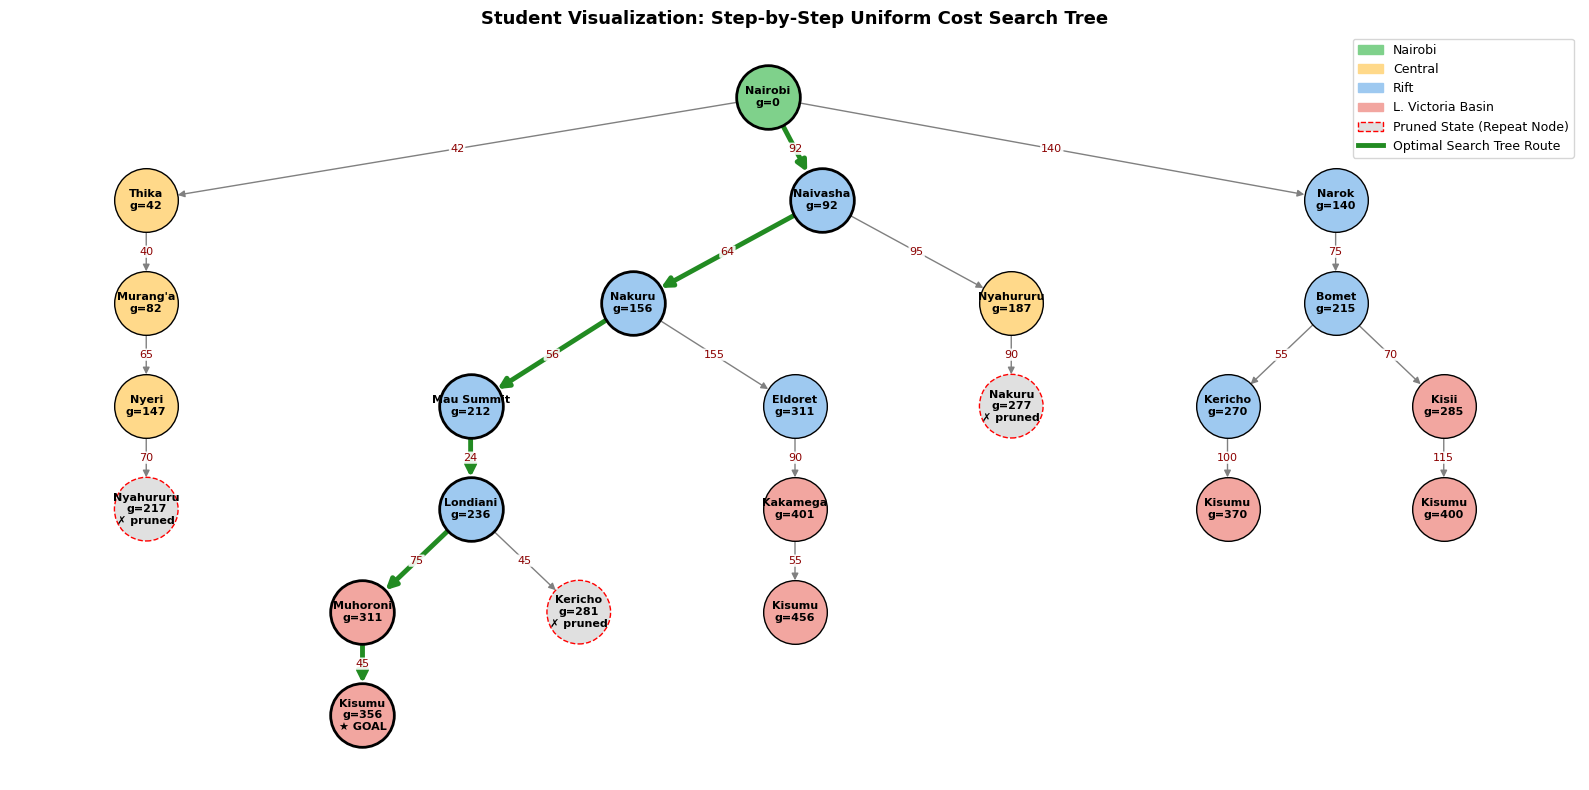

In [10]:
# Visualizing the Highway Network & UCS Search Tree
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx

roads = [
    ("Nairobi", "Thika", 42), ("Thika", "Murang'a", 40),
    ("Murang'a", "Nyeri", 65), ("Nyeri", "Nyahururu", 70),
    ("Nairobi", "Naivasha", 92), ("Naivasha", "Nakuru", 64),
    ("Naivasha", "Nyahururu", 95), ("Nyahururu", "Nakuru", 90),
    ("Nairobi", "Narok", 140), ("Narok", "Bomet", 75),
    ("Nakuru", "Mau Summit", 56), ("Nakuru", "Eldoret", 155),
    ("Mau Summit", "Londiani", 24), ("Londiani", "Muhoroni", 75),
    ("Muhoroni", "Kisumu", 45), ("Londiani", "Kericho", 45),
    ("Bomet", "Kericho", 55), ("Kericho", "Kisumu", 100),
    ("Bomet", "Kisii", 70), ("Kisii", "Kisumu", 115),
    ("Eldoret", "Kakamega", 90), ("Kakamega", "Kisumu", 55),
]

# Grouping towns into regions to color code our map
town_regions = {
    "Nairobi": "Nairobi",
    "Thika": "Central", "Murang'a": "Central", "Nyeri": "Central", "Nyahururu": "Central",
    "Naivasha": "Rift", "Nakuru": "Rift", "Narok": "Rift", "Bomet": "Rift",
    "Mau Summit": "Rift", "Londiani": "Rift", "Eldoret": "Rift", "Kericho": "Rift",
    "Muhoroni": "L. Victoria Basin", "Kisii": "L. Victoria Basin",
    "Kakamega": "L. Victoria Basin", "Kisumu": "L. Victoria Basin"
}

region_colors = {
    "Nairobi": "#7fd18b",           # Light green
    "Central": "#ffd98a",           # Orange/Yellow
    "Rift": "#9ec9f0",              # Light blue
    "L. Victoria Basin": "#f2a6a0"  # Soft red
}

# Create a directed graph since we can travel both directions on roads
G = nx.DiGraph()
for u, v, w in roads:
    G.add_edge(u, v, weight=w)
    G.add_edge(v, u, weight=w)

# Our optimal path found using UCS
opt_path = ["Nairobi", "Naivasha", "Nakuru", "Mau Summit", "Londiani", "Muhoroni", "Kisumu"]
opt_edges = list(zip(opt_path, opt_path[1:]))
# Both directions for coloring purposes
opt_both_directions = set(opt_edges) | {(v, u) for u, v in opt_edges}

# Coordinates to draw towns in a layout that looks geographically correct
town_coords = {
    "Nairobi": (3.2, 0.0),   "Thika": (3.6, 1.2),   "Murang'a": (3.5, 2.2),
    "Nyeri": (3.0, 3.2),     "Nyahururu": (2.0, 3.4), "Naivasha": (2.3, 1.0),
    "Nakuru": (1.5, 2.2),    "Narok": (1.9, -0.9),  "Bomet": (0.9, -1.1),
    "Mau Summit": (1.1, 1.2), "Londiani": (0.6, 0.45), "Kericho": (0.1, -0.2),
    "Eldoret": (0.0, 3.0),   "Muhoroni": (-0.5, 0.5),
    "Kakamega": (-1.4, 2.4), "Kisumu": (-1.6, 0.5), "Kisii": (-1.4, -1.0),
}

# --- Plot 1: Road Network Diagram ---
plt.figure(figsize=(15, 9))
ax1 = plt.gca()

# Draw nodes with their regional colors
node_colors = [region_colors[town_regions[node]] for node in G.nodes()]
nx.draw_networkx_nodes(G, town_coords, node_size=1500, node_color=node_colors,
                       edgecolors="black", linewidths=1.0, ax=ax1)

# Highlight Start and Goal with thick borders
nx.draw_networkx_nodes(G, town_coords, nodelist=["Nairobi", "Kisumu"], node_size=1900,
                       node_color=[region_colors["Nairobi"], region_colors["L. Victoria Basin"]],
                       edgecolors="black", linewidths=2.5, ax=ax1)

# Draw normal edges as gray dashed lines
other_edges = [edge for edge in G.edges() if edge not in opt_both_directions]
nx.draw_networkx_edges(G, town_coords, edgelist=other_edges, width=1.0, edge_color="gray",
                       style="dashed", arrowsize=10, connectionstyle="arc3,rad=0.1", ax=ax1)

# Draw our optimal UCS path as a thick solid green line
x_edges_opt = nx.draw_networkx_edges(G, town_coords, edgelist=opt_edges, width=4.0,
                       edge_color="forestgreen", arrowsize=20, connectionstyle="arc3,rad=0.0", ax=ax1)

# Label nodes with town names
nx.draw_networkx_labels(G, town_coords, font_size=9, font_weight="bold", ax=ax1)

# Label edges with road distances
road_labels = {(u, v): f"{w}" for u, v, w in roads}
nx.draw_networkx_edge_labels(
    G, town_coords, edge_labels=road_labels, font_color="darkred", font_size=9,
    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85), ax=ax1
)

# Legend settings
legend_patches = [mpatches.Patch(color=col, label=reg) for reg, col in region_colors.items()]
legend_patches += [
    plt.Line2D([0], [0], color="forestgreen", lw=4, label="Optimal path (356 km)"),
    plt.Line2D([0], [0], color="gray", lw=1, ls="--", label="Other roads")
]
ax1.legend(handles=legend_patches, loc="lower right", fontsize=10, title="Regions & Paths")
plt.title("Student Visualization: Kenya Road Network for UCS Task", fontsize=13, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()


#  Step 2: Set up the search tree nodes as expanded by our UCS algorithm ---
# Format: (node_id, town_name, path_cost_g, parent_id, is_pruned)
tree_data = [
    ("n0", "Nairobi", 0, None, False),
    ("a1", "Thika", 42, "n0", False), ("a2", "Murang'a", 82, "a1", False),
    ("a3", "Nyeri", 147, "a2", False), ("a4", "Nyahururu", 217, "a3", True),
    ("b1", "Naivasha", 92, "n0", False), ("b2", "Nakuru", 156, "b1", False),
    ("b3", "Mau Summit", 212, "b2", False), ("b4", "Londiani", 236, "b3", False),
    ("b5", "Muhoroni", 311, "b4", False), ("b6", "Kisumu", 356, "b5", False),
    ("b7", "Kericho", 281, "b4", True),
    ("b8", "Eldoret", 311, "b2", False), ("b9", "Kakamega", 401, "b8", False),
    ("b10", "Kisumu", 456, "b9", False),
    ("b11", "Nyahururu", 187, "b1", False), ("b12", "Nakuru", 277, "b11", True),
    ("c1", "Narok", 140, "n0", False), ("c2", "Bomet", 215, "c1", False),
    ("c3", "Kericho", 270, "c2", False), ("c4", "Kisumu", 370, "c3", False),
    ("c5", "Kisii", 285, "c2", False), ("c6", "Kisumu", 400, "c5", False),
]

T = nx.DiGraph()
tree_nodes_info = {}
for nid, town, g, parent, pruned in tree_data:
    T.add_node(nid)
    tree_nodes_info[nid] = (town, g, pruned)
    if parent:
        T.add_edge(parent, nid)

# Simple recursive function to layout the tree neatly
tree_positions = {}
leaf_counter = [0]

def layout_tree(node, current_depth):
    children = list(T.successors(node))
    if not children:
        tree_positions[node] = (leaf_counter[0], -current_depth)
        leaf_counter[0] += 1
    else:
        for child in children:
            layout_tree(child, current_depth + 1)
        # Position parent at the horizontal center of its children
        avg_x = sum(tree_positions[child][0] for child in children) / len(children)
        tree_positions[node] = (avg_x, -current_depth)

# Compute layout positions starting from root
layout_tree("n0", 0)

# Nodes that are part of our optimal solution path
opt_node_ids = {"n0", "b1", "b2", "b3", "b4", "b5", "b6"}

# --- Plot 2: UCS Search Tree Diagram ---
plt.figure(figsize=(16, 8))
ax2 = plt.gca()

# Draw normal tree edges
normal_tree_edges = [edge for edge in T.edges() if not (edge[0] in opt_node_ids and edge[1] in opt_node_ids)]
nx.draw_networkx_edges(T, tree_positions, edgelist=normal_tree_edges, edge_color="gray",
                       arrows=True, arrowsize=10, node_size=2100, ax=ax2)

# Highlight the optimal path taken by UCS in green
opt_tree_edges = [(u, v) for u, v in T.edges() if u in opt_node_ids and v in opt_node_ids]
nx.draw_networkx_edges(T, tree_positions, edgelist=opt_tree_edges, edge_color="forestgreen",
                       width=3.5, arrows=True, arrowsize=15, node_size=2100, ax=ax2)

# Draw nodes one by one with customized labels and styles
for nid, (town, g, pruned) in tree_nodes_info.items():
    if pruned:
        node_color = "#e0e0e0"
        border_color = "red"
        line_style = "--"
        label_text = f"{town}\ng={g}\n✗ pruned"
    else:
        node_color = region_colors[town_regions[town]]
        border_color = "black"
        line_style = "-"
        label_text = f"{town}\ng={g}"
        if nid == "b6":
            label_text = f"{town}\ng={g}\n★ GOAL"

    linewidth = 2.0 if nid in opt_node_ids else 1.0

    ax2.scatter(*tree_positions[nid], s=2100, c=node_color, edgecolors=border_color,
                linewidths=linewidth, linestyle=line_style, zorder=3)
    ax2.text(*tree_positions[nid], label_text, ha="center", va="center", fontsize=8,
             fontweight="bold", zorder=4)

# Draw path costs on edges of the tree
for parent, child in T.edges():
    x_mid = (tree_positions[parent][0] + tree_positions[child][0]) / 2
    y_mid = (tree_positions[parent][1] + tree_positions[child][1]) / 2
    cost_diff = tree_nodes_info[child][1] - tree_nodes_info[parent][1]
    ax2.text(x_mid, y_mid, f"{cost_diff}", color="darkred", fontsize=8, ha="center", va="center",
             bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.9), zorder=5)

# Map elements legend
tree_legend_patches = [mpatches.Patch(color=col, label=reg) for reg, col in region_colors.items()]
tree_legend_patches += [
    mpatches.Patch(facecolor="#e0e0e0", edgecolor="red", linestyle="--", label="Pruned State (Repeat Node)"),
    plt.Line2D([0], [0], color="forestgreen", lw=3.5, label="Optimal Search Tree Route")
]
ax2.legend(handles=tree_legend_patches, loc="upper right", fontsize=9)

plt.title("Student Visualization: Step-by-Step Uniform Cost Search Tree", fontsize=13, fontweight="bold")
plt.axis("off")
plt.margins(0.05)
plt.tight_layout()
plt.show()